## Import python modules

In [2]:
import numpy as np
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt
import xarray as xr
from PIL import Image

In [3]:
filters = ['01', '02','03','07']
filters_label = ['0.1-1.0 Hz','0.5-1.0 Hz','0.4-0.8 Hz','1.0-2.0 Hz']
files = glob.glob('../data/RNE_dvv/STR/**/NZ/*csv', recursive=True)

/tmp/ipykernel_436767/1361624924.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_436767/1361624924.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_436767/1361624924.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_436767/1361624924.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_436767/1361624924.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_436767/1361624924.py:9: DtypeWarning: Columns (0) have mixed types. Specify

/tmp/ipykernel_436767/1361624924.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_436767/1361624924.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_436767/1361624924.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_436767/1361624924.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')


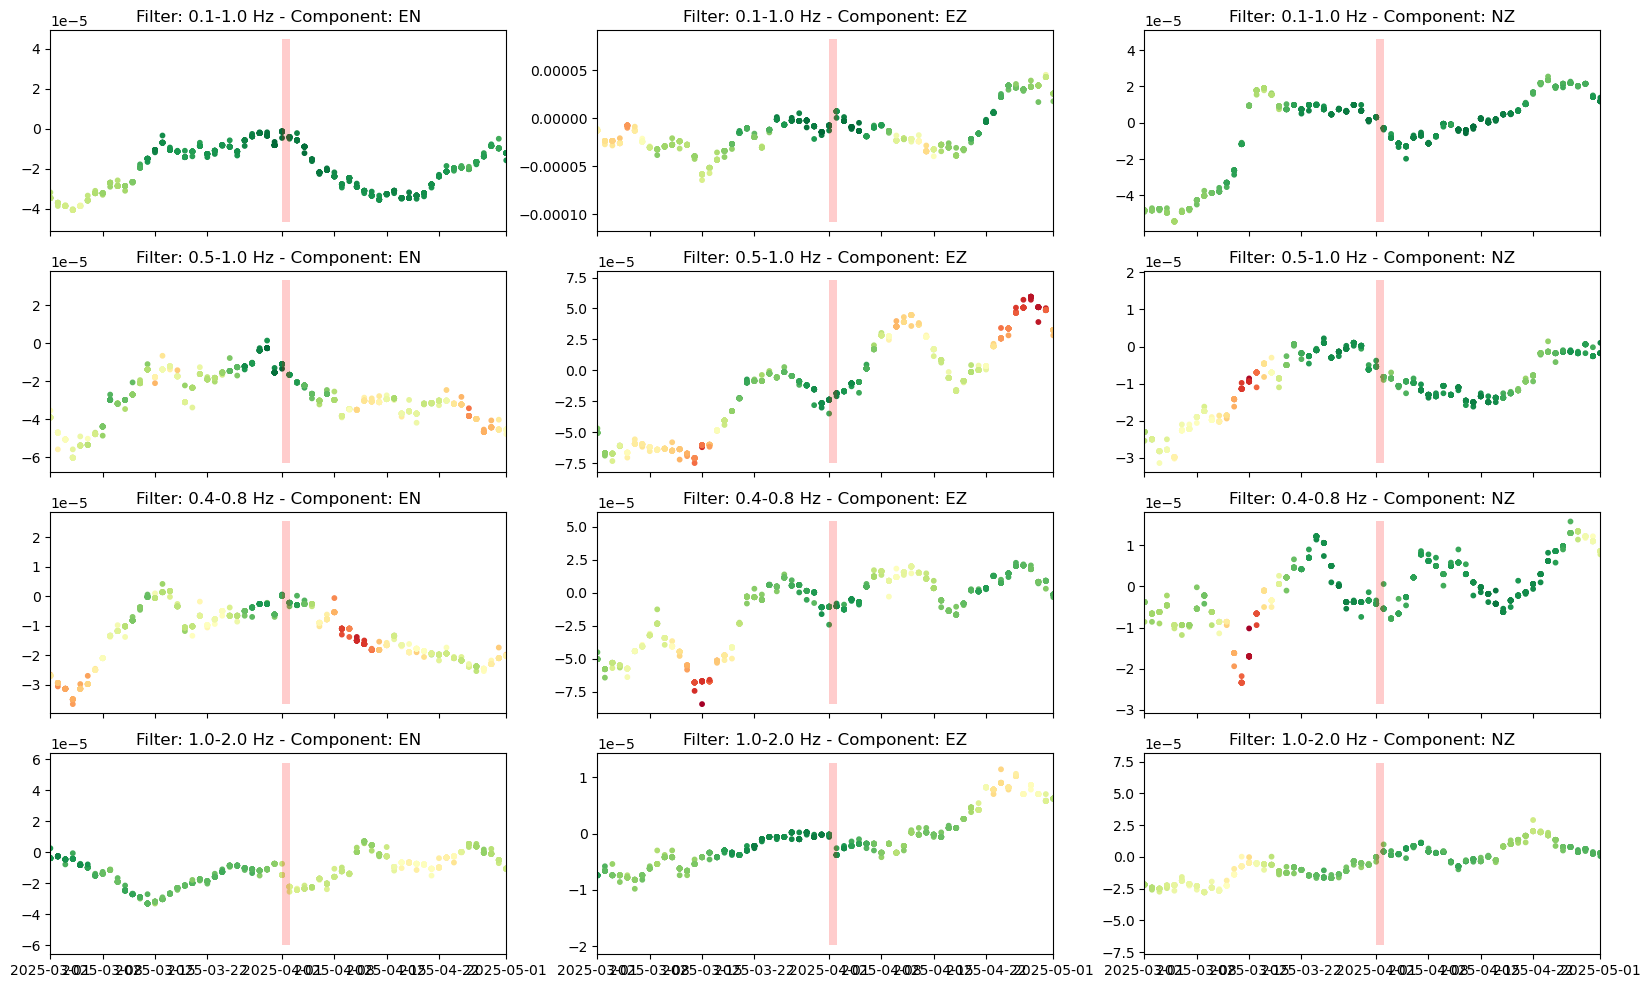

In [3]:
%matplotlib inline
fig, ax = plt.subplots(nrows=4, ncols=3, figsize=(20, 12), sharex=True)
for c,composant in enumerate(['EN', 'EZ', 'NZ']):
    files = glob.glob(f'./RNE_dvv/STR/**/{composant}/*csv', recursive=True)
    files.sort()
    for i, file in enumerate(files):
        info = file.split('/')
        freq = filters_label[filters.index(info[-4])]
        df = pd.read_csv(file, index_col='Date')
          # Resample to daily frequency and take the mean 
        df.index = pd.to_datetime(df.index)
        df.sort_values(by='Date', inplace=True)
        df.resample('D').mean()
        df.dropna(inplace=True)
        # Process the DataFrame as needed
        ax[i % 4][c].scatter(df.index, (df['Delta']-1)/100, s=10, c=df['Coeff'], cmap='RdYlGn', label=filters_label[i % 4])
        #df['Delta'].plot(ax=ax[i % 4])
        ax[i % 4][c].set_title(f'Filter: {freq} - Component: {composant}')
        min_delta = np.min((df['Delta']-1)/100)
        max_delta = np.max((df['Delta']-1)/100)
        ax[i % 4][c].fill_betweenx([min_delta, max_delta], np.datetime64('2024-08-22T21:26'), np.datetime64('2024-09-06T00:00'), facecolor='r', alpha=.2)
        ax[i % 4][c].fill_betweenx([min_delta, max_delta], np.datetime64('2024-11-21T00:14'), np.datetime64('2024-12-02T00:00'), facecolor='r', alpha=.2)
        ax[i % 4][c].fill_betweenx([min_delta, max_delta], np.datetime64('2025-04-01T00:00'), np.datetime64('2025-04-02T00:00'), facecolor='r', alpha=.2)
        ax[i % 4][c].fill_betweenx([min_delta, max_delta], np.datetime64('2025-07-16T04:00'), np.datetime64('2025-08-06T03:59'), facecolor='r', alpha=.2)
        ax[i % 4][c].set_xlim([np.datetime64('2025-03-01T00:00'), np.datetime64('2025-05-01T00:00')])
plt.show()

## DVV vs TEMP GEOTHERM

In [4]:
ds = xr.open_dataset("../fbg_data_r/gunnvher_channel_5_fbg_cleaned_10s.nc")
data = (ds.Wavelength_nm - ds.Wavelength_nm.mean(dim='Time'))
geo_temp  = data.sel(FBG=0).resample(Time='1H').mean()

<string>:6: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.


/tmp/ipykernel_377485/1881382724.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_377485/1881382724.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_377485/1881382724.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_377485/1881382724.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_377485/1881382724.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_377485/1881382724.py:9: DtypeWarning: Columns (0) have mixed types. Specify

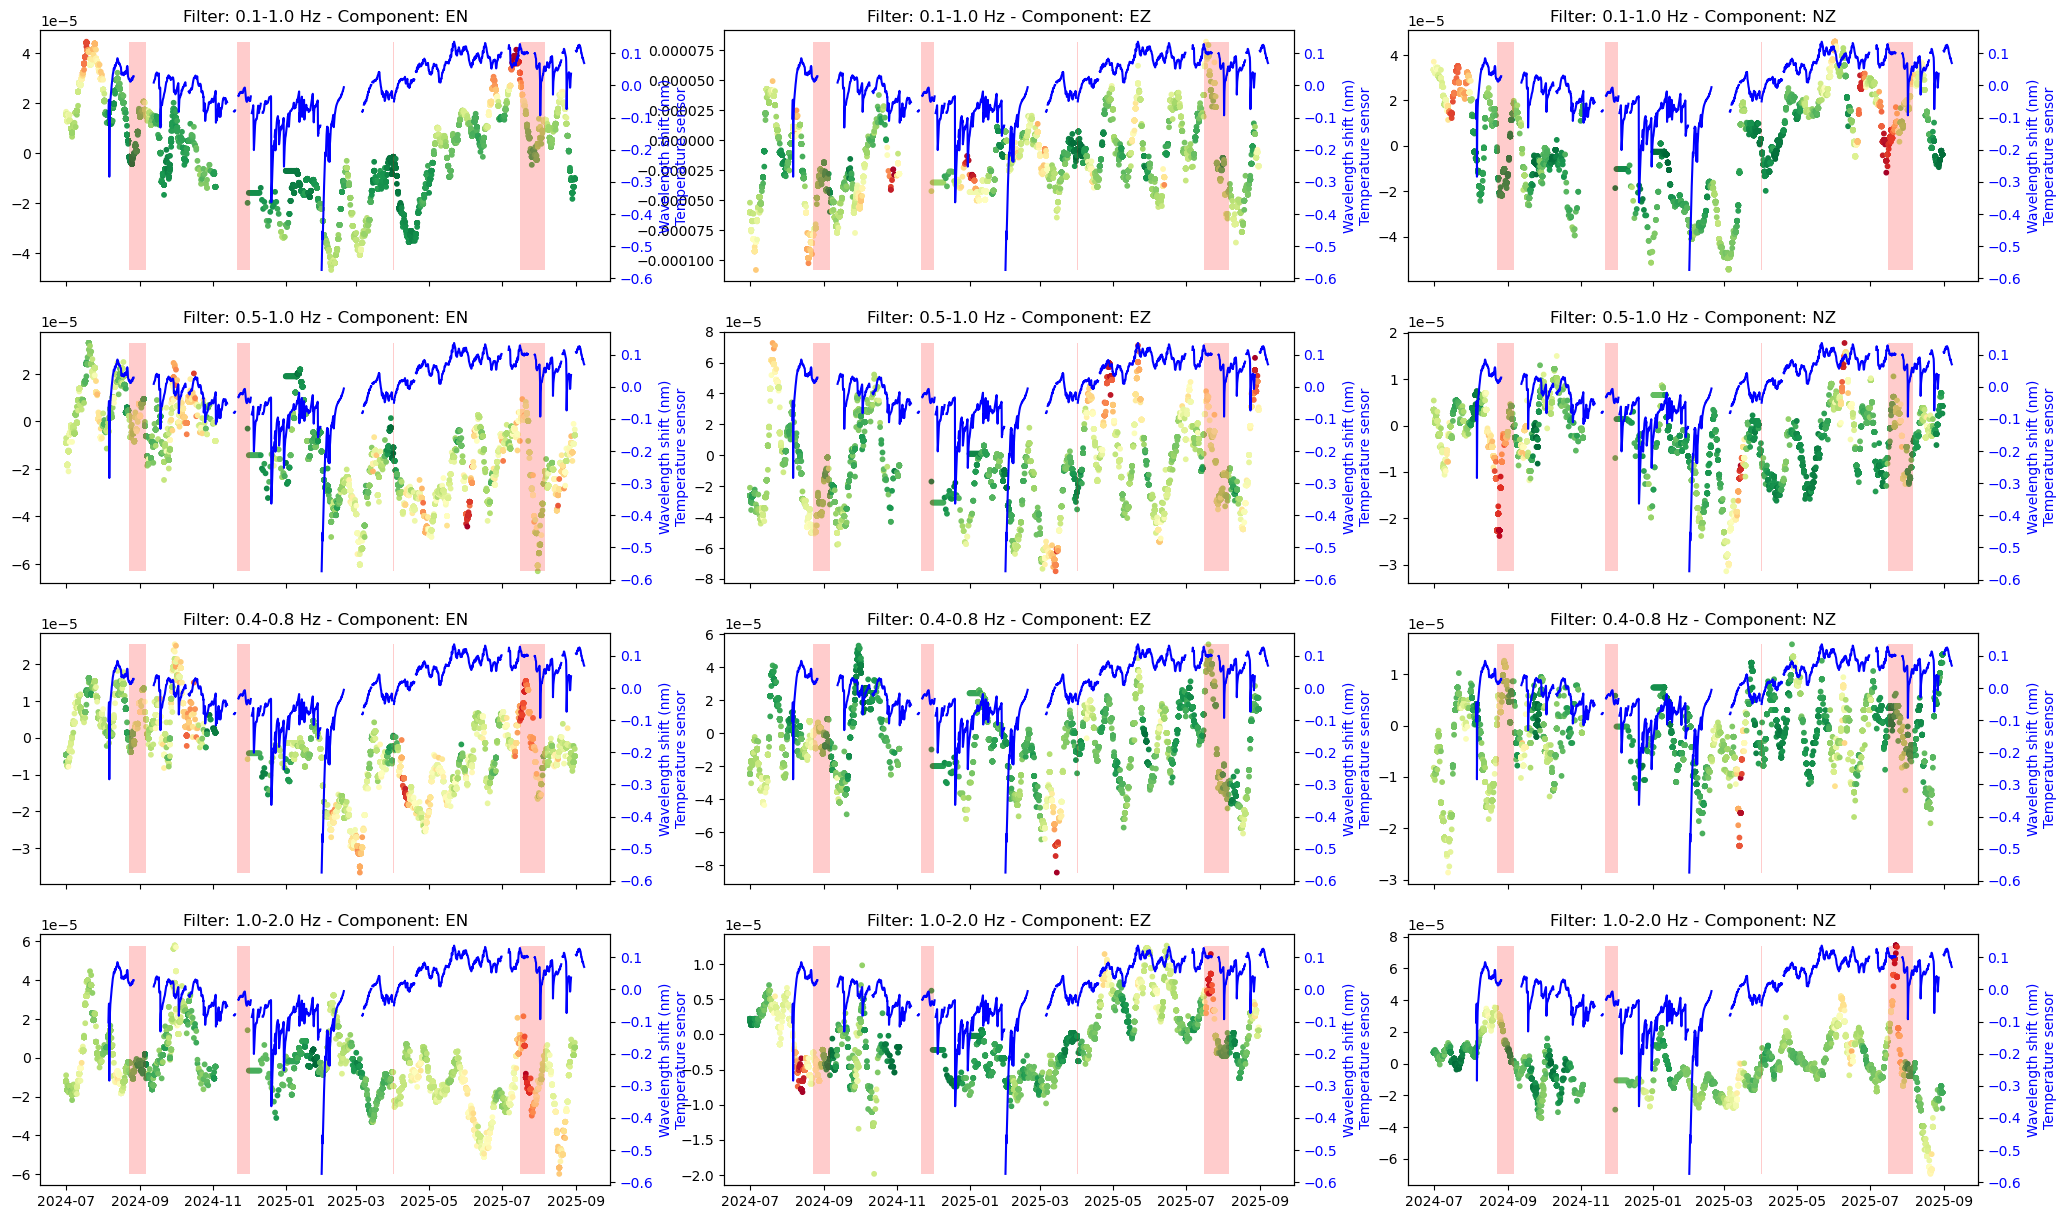

In [5]:
%matplotlib inline
fig, ax = plt.subplots(nrows=4, ncols=3, figsize=(25, 15), sharex=True)
for c,composant in enumerate(['EN', 'EZ', 'NZ']):
    files = glob.glob(f'./RNE_dvv/STR/**/{composant}/*csv', recursive=True)
    files.sort()    
    for i, file in enumerate(files):
        info = file.split('/')
        freq = filters_label[filters.index(info[-4])]
        df = pd.read_csv(file, index_col='Date')
          # Resample to daily frequency and take the mean 
        df.index = pd.to_datetime(df.index)
        df.sort_values(by='Date', inplace=True)
        df.resample('D').mean()
        df.dropna(inplace=True)
        # Process the DataFrame as needed
        ax[i % 4][c].scatter(df.index, (df['Delta']-1)/100, s=10, c=df['Coeff'], cmap='RdYlGn', label=filters_label[i % 4])
        #df['Delta'].plot(ax=ax[i % 4])
        ax[i % 4][c].set_title(f'Filter: {freq} - Component: {composant}')
        min_delta = np.min((df['Delta']-1)/100)
        max_delta = np.max((df['Delta']-1)/100)
        ax[i % 4][c].fill_betweenx([min_delta, max_delta], np.datetime64('2024-08-22T21:26'), np.datetime64('2024-09-06T00:00'), facecolor='r', alpha=.2)
        ax[i % 4][c].fill_betweenx([min_delta, max_delta], np.datetime64('2024-11-21T00:14'), np.datetime64('2024-12-02T00:00'), facecolor='r', alpha=.2)
        ax[i % 4][c].fill_betweenx([min_delta, max_delta], np.datetime64('2025-04-01T00:00'), np.datetime64('2025-04-02T00:00'), facecolor='r', alpha=.2)
        ax[i % 4][c].fill_betweenx([min_delta, max_delta], np.datetime64('2025-07-16T04:00'), np.datetime64('2025-08-06T03:59'), facecolor='r', alpha=.2)

        axb = ax[i % 4][c].twinx()
        axb.plot(geo_temp.Time, geo_temp.values, color='blue', label='Geothermal Temp')
        axb.set_ylabel('Wavelength shift (nm)\nTemperature sensor', color='blue')
        axb.tick_params(axis='y', labelcolor='blue')
plt.show()

## Tilted strain

In [6]:
ds = xr.open_dataset("../fbg_data_r/gunnvher_channel_5_fbg_cleaned_10s.nc")
data = (ds.Wavelength_nm - ds.Wavelength_nm.mean(dim='Time'))
tilted  = data.sel(FBG=1).resample(Time='1H').mean()

<string>:6: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.


/tmp/ipykernel_377485/2482961695.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_377485/2482961695.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_377485/2482961695.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_377485/2482961695.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_377485/2482961695.py:9: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_377485/2482961695.py:9: DtypeWarning: Columns (0) have mixed types. Specify

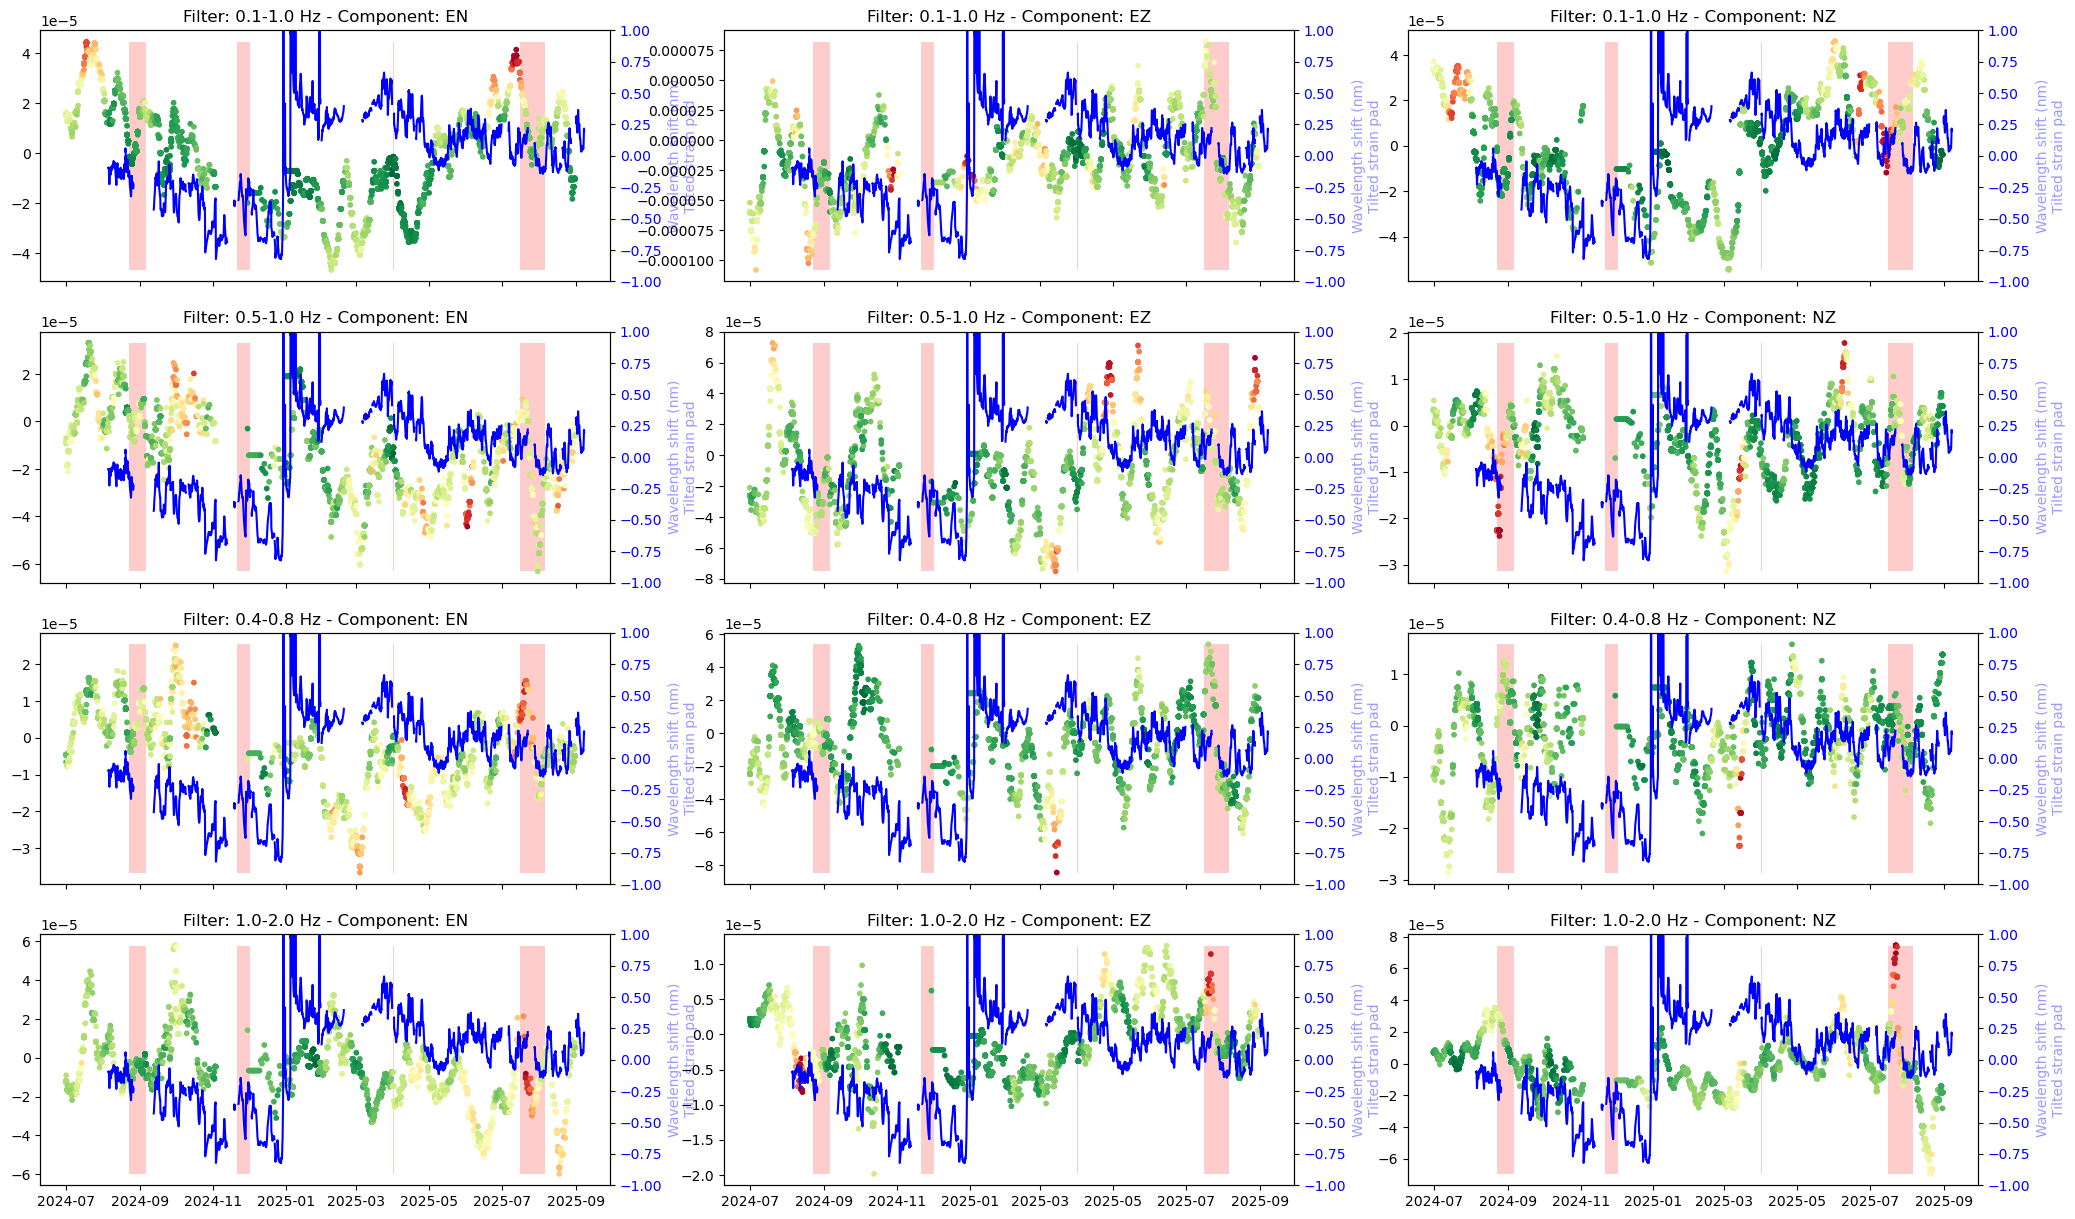

In [7]:
%matplotlib inline
fig, ax = plt.subplots(nrows=4, ncols=3, figsize=(25, 15), sharex=True)
for c,composant in enumerate(['EN', 'EZ', 'NZ']):
    files = glob.glob(f'./RNE_dvv/STR/**/{composant}/*csv', recursive=True)
    files.sort()    
    for i, file in enumerate(files):
        info = file.split('/')
        freq = filters_label[filters.index(info[-4])]
        df = pd.read_csv(file, index_col='Date')
          # Resample to daily frequency and take the mean 
        df.index = pd.to_datetime(df.index)
        df.sort_values(by='Date', inplace=True)
        df.resample('D').mean()
        df.dropna(inplace=True)
        # Process the DataFrame as needed
        ax[i % 4][c].scatter(df.index, (df['Delta']-1)/100, s=10, c=df['Coeff'], cmap='RdYlGn', label=filters_label[i % 4], zorder=2)
        #df['Delta'].plot(ax=ax[i % 4])
        ax[i % 4][c].set_title(f'Filter: {freq} - Component: {composant}')
        min_delta = np.min((df['Delta']-1)/100)
        max_delta = np.max((df['Delta']-1)/100)
        ax[i % 4][c].fill_betweenx([min_delta, max_delta], np.datetime64('2024-08-22T21:26'), np.datetime64('2024-09-06T00:00'), facecolor='r', alpha=.2)
        ax[i % 4][c].fill_betweenx([min_delta, max_delta], np.datetime64('2024-11-21T00:14'), np.datetime64('2024-12-02T00:00'), facecolor='r', alpha=.2)
        ax[i % 4][c].fill_betweenx([min_delta, max_delta], np.datetime64('2025-04-01T00:00'), np.datetime64('2025-04-02T00:00'), facecolor='r', alpha=.2)
        ax[i % 4][c].fill_betweenx([min_delta, max_delta], np.datetime64('2025-07-16T04:00'), np.datetime64('2025-08-06T03:59'), facecolor='r', alpha=.2)

        axb = ax[i % 4][c].twinx()
        axb.plot(tilted.Time, tilted.values, color='blue', label='Geothermal Temp')
        axb.set_ylabel('Wavelength shift (nm)\nTilted strain pad', color='blue', alpha=.4, zorder=1)
        axb.set_ylim(-1, 1)
        axb.tick_params(axis='y', labelcolor='blue')
plt.show()

In [8]:
das_data = xr.open_dataset('../DAS_Caltech/3_das_strain_2025_feb13_may19_proc_ch_2000_2150.h5')

/tmp/ipykernel_377485/1427016419.py:11: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_377485/1427016419.py:11: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_377485/1427016419.py:11: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_377485/1427016419.py:11: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_377485/1427016419.py:11: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, index_col='Date')
/tmp/ipykernel_377485/1427016419.py:11: DtypeWarning: Columns (0) have mixed types. S

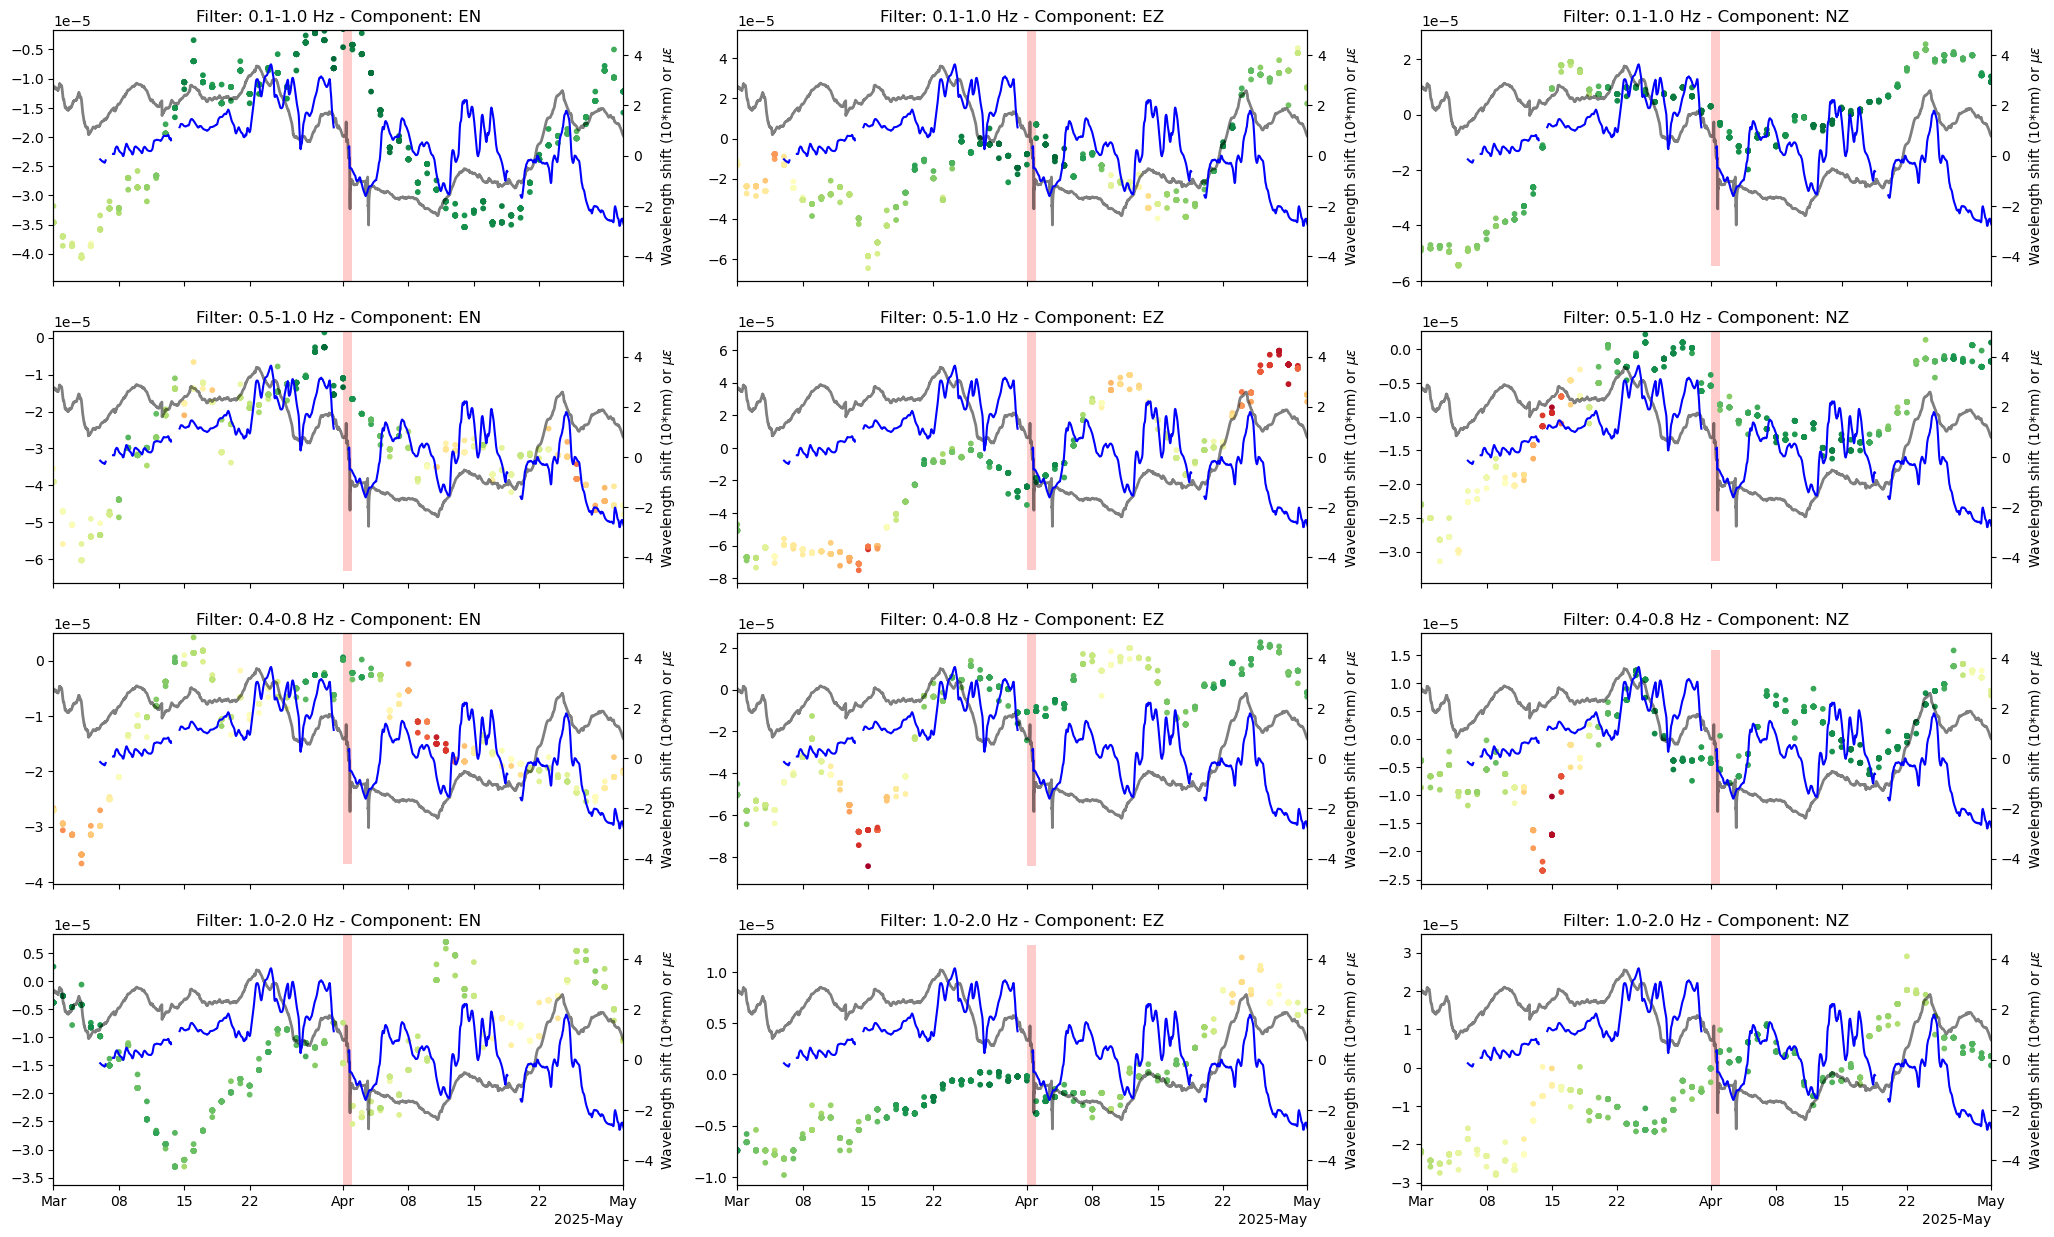

In [9]:
%matplotlib inline
ch1, ch2 =  2105, 2108
#das_data = das_data - das_data.strain.mean(dim='time')
fig, ax = plt.subplots(nrows=4, ncols=3, figsize=(25, 15), sharex=True)
for c,composant in enumerate(['EN', 'EZ', 'NZ']):
    files = glob.glob(f'./RNE_dvv/STR/**/{composant}/*csv', recursive=True)
    files.sort()    
    for i, file in enumerate(files):
        info = file.split('/')
        freq = filters_label[filters.index(info[-4])]
        df = pd.read_csv(file, index_col='Date')
          # Resample to daily frequency and take the mean 
        df.index = pd.to_datetime(df.index)
        df.sort_values(by='Date', inplace=True)
        df.resample('D').mean()
        df.dropna(inplace=True)
        # Process the DataFrame as needed
        ax[i % 4][c].scatter(df.index, (df['Delta']-1)/100, s=10, c=df['Coeff'], cmap='RdYlGn', label=filters_label[i % 4], zorder=2)
        #df['Delta'].plot(ax=ax[i % 4])
        ax[i % 4][c].set_title(f'Filter: {freq} - Component: {composant}')
        min_delta = np.min((df['Delta']-1)/100)
        max_delta = np.max((df['Delta']-1)/100)
        ax[i % 4][c].fill_betweenx([min_delta, max_delta], np.datetime64('2024-08-22T21:26'), np.datetime64('2024-09-06T00:00'), facecolor='r', alpha=.2)
        ax[i % 4][c].fill_betweenx([min_delta, max_delta], np.datetime64('2024-11-21T00:14'), np.datetime64('2024-12-02T00:00'), facecolor='r', alpha=.2)
        ax[i % 4][c].fill_betweenx([min_delta, max_delta], np.datetime64('2025-04-01T00:00'), np.datetime64('2025-04-02T00:00'), facecolor='r', alpha=.2)
        ax[i % 4][c].fill_betweenx([min_delta, max_delta], np.datetime64('2025-07-16T04:00'), np.datetime64('2025-08-06T03:59'), facecolor='r', alpha=.2)
        ax[i % 4][c].set_ylim(-5e-5, 1e-5)
        #axdas = ax[i % 4][c].twinx()

        lim = df.loc[(df.index > np.datetime64('2025-03-01')) & (df.index < np.datetime64('2025-05-01'))], df.loc[(df.index > np.datetime64('2025-03-01')) & (df.index < np.datetime64('2025-05-01'))].max()
        minlim = (lim[0]['Delta'].min()-1)/100
        maxlim = (lim[0]['Delta'].max()-1)/100
        #ax[i % 4][c].set_ylim(df.loc[(df.index > np.datetime64('2025-03-01')) & (df.index < np.datetime64('2025-05-01'))].min(), df.loc[(df.index > np.datetime64('2025-03-01')) & (df.index < np.datetime64('2025-05-01'))].max())
        ax[i % 4][c].set_ylim(minlim - np.abs(minlim/10), maxlim + maxlim*.2)
        axb = ax[i % 4][c].twinx()
        (das_data.strain.sel(channel=slice(ch1,ch2)).mean(dim='channel') + 3).plot(ax=axb, color='k', alpha=.5, lw=2)
        
        
        axb.plot(tilted.Time, tilted.values*10 - 3, color='blue', label='Geothermal Temp')
        axb.set_ylabel('Wavelength shift (10*nm) or $µ\epsilon$', zorder=1)
        axb.set_ylim(-5, 5)
        #axb.tick_params(axis='y', labelcolor='blue')
        ax[i % 4][c].set_xlim(np.datetime64('2025-03-01'), np.datetime64('2025-05-01'))
plt.show()

/tmp/ipykernel_377485/981057776.py:3: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file[0], index_col='Date')


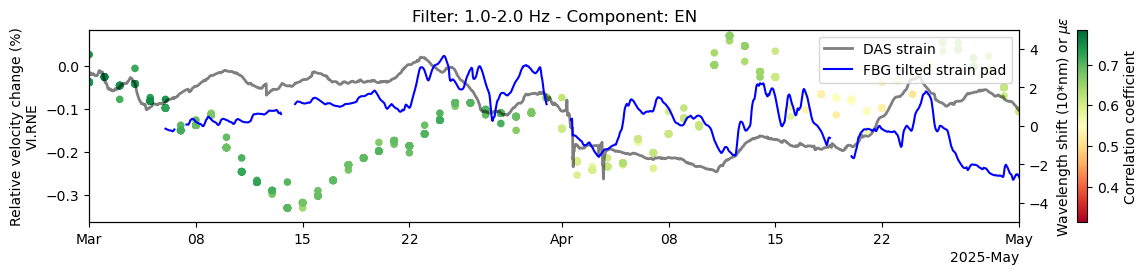

In [10]:
fig, ax = plt.subplots(figsize=(15, 2.5))
file = glob.glob(f'./RNE_dvv/STR/07/**/EN/*csv', recursive=True)
df = pd.read_csv(file[0], index_col='Date')
    # Resample to daily frequency and take the mean 
df.index = pd.to_datetime(df.index)
df.sort_values(by='Date', inplace=True)
df.resample('D').mean()
df.dropna(inplace=True)
# Process the DataFrame as needed
ax.scatter(df.index, (df['Delta']-1)*100, s=20, c=df['Coeff'], cmap='RdYlGn', label=filters_label[i % 4], zorder=2)

#df['Delta'].plot(ax=ax[i % 4])
ax.set_title(f'Filter: 1.0-2.0 Hz - Component: EN')

ax.fill_betweenx([min_delta, max_delta], np.datetime64('2025-04-01T00:00'), np.datetime64('2025-04-02T00:00'), facecolor='r', alpha=.2)
min_delta = np.min((df['Delta']-1)*100)
max_delta = np.max((df['Delta']-1)*100)

lim = df.loc[(df.index > np.datetime64('2025-03-01')) & (df.index < np.datetime64('2025-05-01'))], df.loc[(df.index > np.datetime64('2025-03-01')) & (df.index < np.datetime64('2025-05-01'))].max()
minlim = (lim[0]['Delta'].min()-1)*100
maxlim = (lim[0]['Delta'].max()-1)*100
#ax[i % 4][c].set_ylim(df.loc[(df.index > np.datetime64('2025-03-01')) & (df.index < np.datetime64('2025-05-01'))].min(), df.loc[(df.index > np.datetime64('2025-03-01')) & (df.index < np.datetime64('2025-05-01'))].max())
ax.set_ylim(minlim - np.abs(minlim/10), maxlim + maxlim*.2)
ax.set_ylabel('Relative velocity change (%)\nVI.RNE', zorder=1)
axb = ax.twinx()
(das_data.strain.sel(channel=slice(ch1,ch2)).mean(dim='channel') + 3).plot(ax=axb, color='k', alpha=.5, lw=2, label='DAS strain')


axb.plot(tilted.Time, tilted.values*10 - 3, color='blue', label='FBG tilted strain pad')
axb.set_ylabel('Wavelength shift (10*nm) or $µ\epsilon$', zorder=1)
axb.set_ylim(-5, 5)
axb.legend(loc='upper right')
ax.set_xlim(np.datetime64('2025-03-01'), np.datetime64('2025-05-01'))

fig.colorbar(ax.collections[0], ax=ax, label='Correlation coefficient')

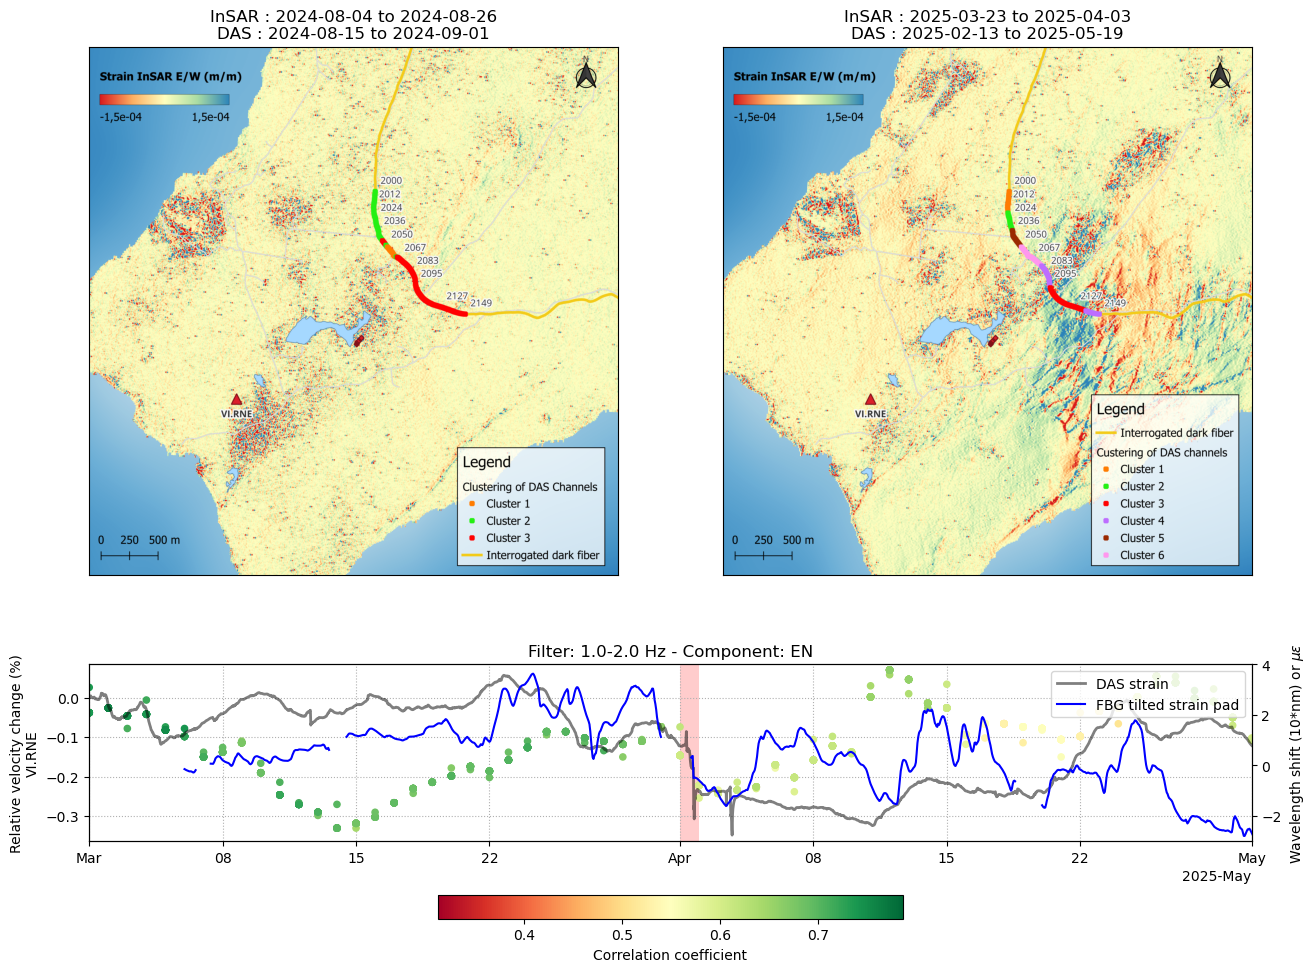

In [12]:
figx = plt.figure(figsize=(15, 12))

ax = plt.subplot2grid((3,2), (0,0), rowspan=2)
ax.imshow(np.asarray(Image.open('inSAR_qgis/period_1_warpped_insar.png')))
ax.set_xticks([]), ax.set_yticks([])
ax.set_title('InSAR : 2024-08-04 to 2024-08-26\nDAS : 2024-08-15 to 2024-09-01')
#ax1 = plt.subplot2grid((3,2), (0,1), rowspan=2)
#ax1.imshow(np.asarray(Image.open('inSAR_qgis/period_2_warpped_insar.png')))
#ax1.set_xticks([]), ax1.set_yticks([])
#ax1.set_title('InSAR : 2024-11-11 to 2024-11-28\nDAS : 2024-09-15 to 2024-12-01')

ax2 = plt.subplot2grid((3,2), (0,1), rowspan=2)
ax2.imshow(np.asarray(Image.open('inSAR_qgis/period_3_warpped_insar_strain.png')))
ax2.set_xticks([]), ax2.set_yticks([])
ax2.set_title('InSAR : 2025-03-23 to 2025-04-03\nDAS : 2025-02-13 to 2025-05-19')

axb = plt.subplot2grid((3,2), (2,0), colspan=2)

axb.scatter(df.index, (df['Delta']-1)*100, s=20, c=df['Coeff'], cmap='RdYlGn', label=filters_label[i % 4], zorder=2)

#df['Delta'].plot(ax=ax[i % 4])
axb.set_title(f'Filter: 1.0-2.0 Hz - Component: EN')

axb.fill_betweenx([min_delta, max_delta], np.datetime64('2025-04-01T00:00'), np.datetime64('2025-04-02T00:00'), facecolor='r', alpha=.2)
min_delta = np.min((df['Delta']-1)*100)
max_delta = np.max((df['Delta']-1)*100)

lim = df.loc[(df.index > np.datetime64('2025-03-01')) & (df.index < np.datetime64('2025-05-01'))], df.loc[(df.index > np.datetime64('2025-03-01')) & (df.index < np.datetime64('2025-05-01'))].max()
minlim = (lim[0]['Delta'].min()-1)*100
maxlim = (lim[0]['Delta'].max()-1)*100
#ax[i % 4][c].set_ylim(df.loc[(df.index > np.datetime64('2025-03-01')) & (df.index < np.datetime64('2025-05-01'))].min(), df.loc[(df.index > np.datetime64('2025-03-01')) & (df.index < np.datetime64('2025-05-01'))].max())
axb.set_ylim(minlim - np.abs(minlim/10), maxlim + maxlim*.2)
axb.set_ylabel('Relative velocity change (%)\nVI.RNE', zorder=1)
axb.grid(ls=':')
axc = axb.twinx()
(das_data.strain.sel(channel=slice(ch1,ch2)).mean(dim='channel') + 3).plot(ax=axc, color='k', alpha=.5, lw=2, label='DAS strain')


axc.plot(tilted.Time, tilted.values*10 - 3, color='blue', label='FBG tilted strain pad')
axc.set_ylabel('Wavelength shift (10*nm) or $µ\epsilon$', zorder=1)
axc.set_ylim(-3, 4)
axc.legend(loc='upper right')
axb.set_xlim(np.datetime64('2025-03-01'), np.datetime64('2025-05-01'))
figx.colorbar(axb.collections[0], ax=axb, label='Correlation coefficient', orientation='horizontal', pad=0.2, shrink=0.4, )
plt.savefig('./plots/dvv_fbg_das_insar_strain.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()
